# Checkpoint 3 — Clustering e segmentação de clientes

**Disciplina: Modelagem Linear para Aprendizado de Máquina**  
**Atividade prática em Python | K-Means, Elbow e Silhouette Score**

**Nome(s) e RM(s):** Felipe Macedo — RM 570990 (único integrante)  
**Turma:** _preencher_

## Situação-problema

Uma empresa de comércio eletrônico deseja conhecer os diferentes perfis de compra de seus clientes para planejar ações de relacionamento. Cada registro reúne o histórico de um cliente nos últimos 12 meses, calculado na mesma data de referência.

Seu desafio é identificar grupos de clientes com comportamentos semelhantes, justificar a quantidade de clusters e propor uma ação coerente para cada perfil encontrado.

Não há uma coluna com a classificação correta. A qualidade da análise depende da preparação dos dados, das evidências apresentadas e da interpretação dos agrupamentos.

## O que desenvolver

1. Explorar a base e selecionar as variáveis.
2. Padronizar as variáveis numéricas.
3. Aplicar K-Means e investigar diferentes valores de **k**.
4. Construir os gráficos de **Elbow** e **Silhouette Score**.
5. Justificar o k escolhido, visualizar os grupos e interpretar seus perfis.
6. Apresentar conclusões e limitações da análise.

As células de importação e leitura estão prontas. Complete as demais células de código e os espaços de resposta. Execute o notebook na ordem, mantendo os resultados visíveis.


## 1. Conheça a base

Esta base contém **120 clientes fictícios**. Os dados foram gerados previamente com NumPy e semente 303, para fins didáticos, e estão incorporados neste notebook como texto CSV. **Não foram coletados de pessoas, empresas ou bases públicas.** A célula de leitura apenas carrega os dados; não gera novos valores.

| Coluna | Significado | Unidade / uso |
| --- | --- | --- |
| `id_cliente` | Identificador fictício do cliente | Identificação; excluir do modelo |
| `gasto_total_12_meses` | Soma dos valores das compras nos últimos 12 meses | R$ |
| `quantidade_compras_12_meses` | Número de compras realizadas nos últimos 12 meses | Compras |
| `dias_desde_ultima_compra` | Dias entre a compra mais recente e a data de referência | Dias |

O gasto descreve o valor acumulado; a quantidade informa a frequência de compras; o tempo desde a última compra representa a recência. Um valor menor de dias indica uma compra mais recente.

Clientes com gasto semelhante podem ter quantidades de compras e recências diferentes. Essas medidas não informam renda, satisfação ou o motivo de um cliente deixar de comprar.

Não substitua a base. Use as três variáveis numéricas no agrupamento principal.


In [1]:
# Bibliotecas utilizadas na atividade.
from io import StringIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

plt.rcParams['figure.figsize'] = (9, 5)


In [2]:
# Base simulada incorporada ao notebook: não é necessário baixar um CSV.
DADOS_CSV = """
id_cliente,gasto_total_12_meses,quantidade_compras_12_meses,dias_desde_ultima_compra
CL001,2415.04,22,14
CL002,6136.88,7,87
CL003,8520.86,31,16
CL004,712.95,1,132
CL005,7964.46,6,104
CL006,897.35,5,99
CL007,606.06,6,108
CL008,8132.06,10,98
CL009,8992.43,30,9
CL010,8439.0,32,4
CL011,3086.0,21,14
CL012,3505.35,17,28
CL013,3824.73,17,18
CL014,14019.61,19,14
CL015,2114.77,23,21
CL016,1161.25,2,122
CL017,6691.19,7,78
CL018,7312.2,4,95
CL019,711.17,5,177
CL020,8414.07,26,0
CL021,7911.54,6,38
CL022,2076.62,22,12
CL023,8985.03,6,45
CL024,7249.79,5,99
CL025,5784.63,8,82
CL026,7510.04,24,14
CL027,996.41,2,147
CL028,3031.75,25,19
CL029,648.73,4,51
CL030,533.45,5,50
CL031,9298.68,6,74
CL032,7208.79,22,10
CL033,6105.18,6,84
CL034,2043.65,26,15
CL035,6791.38,7,50
CL036,554.34,3,95
CL037,8296.09,44,16
CL038,2567.37,16,12
CL039,9130.6,26,13
CL040,3430.01,30,19
CL041,8305.2,34,9
CL042,5551.75,7,58
CL043,7431.23,10,58
CL044,1006.79,6,57
CL045,6493.35,6,90
CL046,5545.24,11,92
CL047,3131.7,25,7
CL048,2725.2,24,11
CL049,1024.4,5,60
CL050,825.75,4,66
CL051,5015.92,4,80
CL052,2768.34,19,34
CL053,6684.99,7,54
CL054,3195.3,30,9
CL055,10387.5,30,12
CL056,876.94,6,54
CL057,624.05,5,104
CL058,956.59,3,167
CL059,12263.9,32,14
CL060,1183.14,2,109
CL061,6823.82,5,42
CL062,6533.72,6,80
CL063,11253.35,27,0
CL064,7448.21,23,8
CL065,1053.25,4,110
CL066,5618.55,19,10
CL067,2422.63,20,28
CL068,8860.03,31,9
CL069,11409.28,24,12
CL070,2554.03,26,16
CL071,648.36,2,64
CL072,1625.9,18,13
CL073,924.97,5,98
CL074,806.85,5,155
CL075,11288.98,24,12
CL076,5693.5,2,86
CL077,2157.1,25,10
CL078,6570.68,7,37
CL079,2288.58,20,13
CL080,420.04,5,89
CL081,7737.84,16,22
CL082,7535.89,5,25
CL083,8534.53,19,15
CL084,6270.62,7,137
CL085,5923.75,26,23
CL086,1154.26,6,122
CL087,4933.71,7,90
CL088,658.41,4,151
CL089,10109.2,20,7
CL090,9140.44,32,0
CL091,7116.95,7,103
CL092,2173.18,25,5
CL093,6307.09,7,67
CL094,4787.96,5,65
CL095,715.66,3,79
CL096,12276.45,23,8
CL097,7253.65,27,14
CL098,710.74,5,130
CL099,9069.7,4,65
CL100,3510.14,24,14
CL101,940.47,3,111
CL102,2393.85,30,21
CL103,5512.15,5,106
CL104,2574.35,23,6
CL105,8571.63,19,7
CL106,2021.96,22,8
CL107,3505.47,7,16
CL108,2254.15,25,18
CL109,701.64,4,38
CL110,2018.77,32,10
CL111,2920.7,21,18
CL112,1120.58,5,86
CL113,1339.64,3,108
CL114,3017.75,28,5
CL115,9374.86,29,12
CL116,485.39,4,132
CL117,6896.28,25,10
CL118,8717.02,42,10
CL119,10309.74,28,16
CL120,2676.42,17,12
"""
df = pd.read_csv(StringIO(DADOS_CSV))
print(df.head().to_string(index=False))
print(f"Clientes: {len(df)}")


id_cliente  gasto_total_12_meses  quantidade_compras_12_meses  dias_desde_ultima_compra
     CL001               2415.04                           22                        14
     CL002               6136.88                            7                        87
     CL003               8520.86                           31                        16
     CL004                712.95                            1                       132
     CL005               7964.46                            6                       104
Clientes: 120


## 2. Exploração dos dados — 1,0 ponto

Apresente o tamanho da base, os tipos das colunas, a quantidade de valores ausentes e as estatísticas descritivas das três variáveis numéricas. Verifique se os identificadores se repetem.

Responda: quais variáveis apresentam maior amplitude? Por que usar apenas o gasto total poderia esconder diferenças de comportamento?


In [3]:
# Lista das variáveis comportamentais que vamos analisar (id_cliente fica de fora:
# é só um rótulo, não descreve comportamento de compra).
variaveis = ['gasto_total_12_meses', 'quantidade_compras_12_meses', 'dias_desde_ultima_compra']

print("Tamanho da base (linhas, colunas):", df.shape)
print("\nTipos das colunas:")
df.info()

print("\nValores ausentes por coluna:")
print(df.isna().sum())

# Se algum id se repetisse, o mesmo cliente pesaria duas vezes no agrupamento.
print("\nIdentificadores repetidos:", df['id_cliente'].duplicated().sum())

print("\nEstatísticas descritivas:")
display(df[variaveis].describe().round(2))

# Amplitude = máximo - mínimo. Mostra o "tamanho" de cada escala.
# Coeficiente de variação = desvio / média: dispersão relativa, sem depender da unidade.
resumo_escala = pd.DataFrame({
    'minimo': df[variaveis].min(),
    'maximo': df[variaveis].max(),
    'amplitude': df[variaveis].max() - df[variaveis].min(),
    'desvio_padrao': df[variaveis].std(),
    'coef_variacao': df[variaveis].std() / df[variaveis].mean(),
}).round(2)
display(resumo_escala)

# Exemplo concreto: clientes com gasto quase igual e comportamentos opostos.
exemplo = df[df['id_cliente'].isin(['CL024', 'CL097', 'CL018', 'CL064'])]
display(exemplo)


Tamanho da base (linhas, colunas): (120, 4)

Tipos das colunas:
<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 4 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   id_cliente                   120 non-null    str    
 1   gasto_total_12_meses         120 non-null    float64
 2   quantidade_compras_12_meses  120 non-null    int64  
 3   dias_desde_ultima_compra     120 non-null    int64  
dtypes: float64(1), int64(2), str(1)
memory usage: 3.9 KB

Valores ausentes por coluna:
id_cliente                     0
gasto_total_12_meses           0
quantidade_compras_12_meses    0
dias_desde_ultima_compra       0
dtype: int64

Identificadores repetidos: 0

Estatísticas descritivas:


,gasto_total_12_meses,quantidade_compras_12_meses,dias_desde_ultima_compra
count,120.00,120.00,120.00
mean,4829.03,14.97,50.93
std,3465.47,10.81,45.41
min,420.04,1.00,0.00
25%,1554.34,5.00,12.00
50%,4306.34,10.50,31.00
75%,7516.50,24.25,87.50
max,14019.61,44.00,177.00


,minimo,maximo,amplitude,desvio_padrao,coef_variacao
gasto_total_12_meses,420.04,14019.61,13599.57,3465.47,0.72
quantidade_compras_12_meses,1.00,44.00,43.00,10.81,0.72
dias_desde_ultima_compra,0.00,177.00,177.00,45.41,0.89


,id_cliente,gasto_total_12_meses,quantidade_compras_12_meses,dias_desde_ultima_compra
17,CL018,7312.20,4,95
23,CL024,7249.79,5,99
63,CL064,7448.21,23,8
96,CL097,7253.65,27,14


**Resposta e observações:**

- A base tem **120 linhas e 4 colunas**, **nenhum valor ausente** e **nenhum `id_cliente` repetido**. As três variáveis do modelo são numéricas (`float64` para gasto e `int64` para compras e dias); `id_cliente` é texto e será excluído do modelo.
- **Amplitudes:** o gasto total vai de R\$ 420,04 a R\$ 14.019,61 (**amplitude ≈ R\$ 13.599,57**); dias desde a última compra vão de 0 a 177 (**amplitude 177 dias**); quantidade de compras vai de 1 a 44 (**amplitude 43 compras**). Em números absolutos, o **gasto** tem de longe a maior amplitude, seguido pelos **dias**. Em termos relativos (coeficiente de variação), a recência é a mais dispersa (0,89), enquanto gasto e quantidade ficam em torno de 0,72.
- O desvio padrão do gasto (≈ 3.465) é cerca de 76 vezes o dos dias (≈ 45) e 320 vezes o da quantidade (≈ 10,8). Sem padronização, o gasto dominaria qualquer cálculo de distância.
- A distribuição de dias é assimétrica: mediana de 31 dias e média de 50,9, puxada por clientes que estão há mais de 100 dias sem comprar.

**Por que usar apenas o gasto total esconderia diferenças?** O gasto é o resultado de *quantas vezes* o cliente comprou e *quanto gastou por vez*, e não diz *quando* foi a última compra. Na própria base, **CL024** (R\$ 7.249,79, 5 compras, 99 dias) e **CL097** (R\$ 7.253,65, 27 compras, 14 dias) têm praticamente o mesmo gasto, mas o primeiro faz poucas compras de valor alto e está há mais de três meses sem comprar, enquanto o segundo compra com frequência e recentemente. Com uma só variável eles cairiam no mesmo grupo e receberiam a mesma ação, embora exijam estratégias diferentes (possível reativação × fidelização).


## 3. Preparação e padronização — 1,5 ponto

Crie `X` com as três variáveis numéricas, preservando `df` nas unidades originais. Use `StandardScaler` para criar `X_padronizado`.

Como as escalas diferem, uma variável pode dominar as distâncias. O `StandardScaler` centraliza e divide pelo desvio padrão; ele não converte os dados para o intervalo de 0 a 1. Explique por que essa transformação é pertinente neste problema.

**Cuidado:** não inclua `id_cliente` nem os rótulos dos clusters entre as variáveis do modelo. Use a mesma matriz padronizada para ajustar e avaliar os agrupamentos.


In [4]:
# X recebe apenas as três variáveis comportamentais. Usamos .copy() para que
# nenhuma operação posterior altere df, que deve permanecer nas unidades originais.
X = df[variaveis].copy()

# StandardScaler aplica z = (x - média) / desvio padrão em cada coluna.
# fit aprende média e desvio; transform aplica a fórmula. O resultado é um array NumPy.
scaler = StandardScaler()
X_padronizado = scaler.fit_transform(X)

# Conferência: médias e desvios aprendidos pelo scaler (unidades originais).
display(pd.DataFrame({'media_aprendida': scaler.mean_,
                      'desvio_aprendido': scaler.scale_}, index=variaveis).round(2))

# Conferência do resultado: cada coluna deve ter média ~0 e desvio ~1.
X_pad_df = pd.DataFrame(X_padronizado, columns=variaveis)
display(X_pad_df.describe().loc[['mean', 'std', 'min', 'max']].round(3))

# Observação: os valores NÃO ficam entre 0 e 1 (há negativos e valores > 1).
# Isso é esperado: o StandardScaler não é um MinMaxScaler.
print("df continua em unidades originais:")
display(df.head(3))


,media_aprendida,desvio_aprendido
gasto_total_12_meses,4829.03,3451.00
quantidade_compras_12_meses,14.97,10.77
dias_desde_ultima_compra,50.93,45.22


,gasto_total_12_meses,quantidade_compras_12_meses,dias_desde_ultima_compra
mean,0.000,-0.000,0.000
std,1.004,1.004,1.004
min,-1.278,-1.297,-1.126
max,2.663,2.696,2.788


df continua em unidades originais:


,id_cliente,gasto_total_12_meses,quantidade_compras_12_meses,dias_desde_ultima_compra
0,CL001,2415.04,22,14
1,CL002,6136.88,7,87
2,CL003,8520.86,31,16


**Justificativa da padronização:**

O K-Means agrupa por **distância euclidiana**. Nas unidades originais, uma diferença de R\$ 1.000 no gasto valeria numericamente o mesmo que 1.000 dias ou 1.000 compras, o que não faz sentido. Como o desvio padrão do gasto (≈ R\$ 3.465) é muito maior que o dos dias (≈ 45) e o da quantidade (≈ 10,8), praticamente toda a distância entre dois clientes viria do gasto, e o modelo ignoraria frequência e recência — exatamente as informações que, como vimos, diferenciam clientes com gasto parecido.

O `StandardScaler` transforma cada variável em $z = (x - \mu)/\sigma$. Depois disso, as três têm **média 0 e desvio padrão 1** (confirmado na tabela acima; o `describe()` mostra 1,004 porque o pandas calcula o desvio com n − 1, enquanto o `StandardScaler` usa n), e uma unidade em qualquer eixo passa a significar "um desvio padrão acima/abaixo da média". Assim, cada variável contribui de forma comparável para a distância. Os valores **não** ficam entre 0 e 1: há valores negativos (abaixo da média) e acima de 1 (ex.: o máximo de dias vira ≈ 2,79).

A padronização preserva a forma da distribuição e a ordem dos clientes; só muda a escala. `df` foi mantido intacto para que a interpretação dos perfis seja feita em reais, compras e dias.


## Apoio: centroides, inércia e distorções

O **centroide** é a média das coordenadas dos pontos de um grupo. O K-Means procura grupos compactos ao reduzir a soma das distâncias quadráticas dos pontos aos centroides atribuídos.

A **inércia**, disponível em `modelo.inertia_`, é essa soma:

$$J = \sum_{i=1}^{n}\left\|x_i-\mu_{c(i)}\right\|^2$$

Por exemplo, gastos de R$ 100, R$ 120 e R$ 140 formam um grupo com centroide de R$ 120. Usando apenas essa variável, sem padronização:

$$J=(100-120)^2+(120-120)^2+(140-120)^2=800$$

Esse 800 é uma medida de dispersão em reais ao quadrado; não é o total gasto pelos clientes.

Neste notebook, **distorções** será o nome da lista que armazena os valores de `inertia_`; aqui, os dois termos se referem à mesma medida. Em outros materiais, distorção pode designar uma média; confira a definição usada.

Com variáveis padronizadas, a inércia é calculada nesse espaço transformado. Ela não representa dinheiro gasto. Compare valores obtidos com as mesmas variáveis e a mesma preparação.


## 4. Método Elbow — 1,5 ponto

Ajuste um K-Means para cada **k de 1 a 8** sobre `X_padronizado`. Use `random_state=42` e `n_init=10` em todos os ajustes para tornar a comparação reproduzível no mesmo ambiente. Armazene `inertia_` na lista `distorcoes` e construa um gráfico com k no eixo horizontal e inércia no vertical.

**Como ler:** aumentar k tende a reduzir a inércia. Procure a região em que as quedas passam a ser menores: o possível cotovelo. Isso indica ganho adicional reduzido ao criar mais grupos, sem determinar sozinho a melhor solução.

Exemplo ilustrativo, sem relação com a base: inércias 900, 460, 210, 190 e 176 para k de 1 a 5 sugerem investigar k = 3. A queda de 2 para 3 é grande; as seguintes são menores. Algumas bases não apresentam cotovelo nítido.

Indique a região candidata observada no seu gráfico e explique a mudança das quedas de inércia.


,k,inercia,queda,queda_%
0,1,360.00,NaN,NaN
1,2,164.71,195.29,54.25
2,3,110.52,54.19,32.90
3,4,60.65,49.87,45.12
4,5,46.92,13.73,22.63
5,6,40.08,6.84,14.57
6,7,33.75,6.33,15.80
7,8,28.41,5.34,15.82


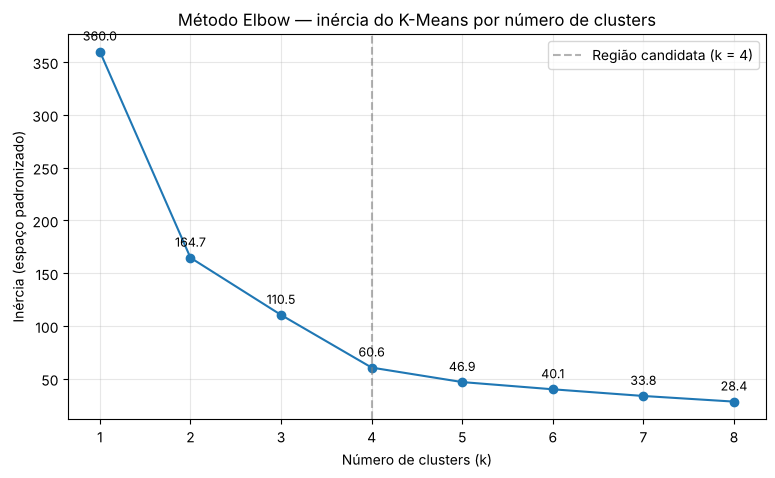

In [5]:
valores_k = range(1, 9)
distorcoes = []   # inércia (soma das distâncias quadráticas aos centroides) para cada k

for k in valores_k:
    # random_state fixa a inicialização; n_init=10 roda 10 inicializações e
    # guarda a de menor inércia, reduzindo o risco de um mínimo local ruim.
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    modelo.fit(X_padronizado)
    distorcoes.append(modelo.inertia_)

tabela_elbow = pd.DataFrame({'k': list(valores_k), 'inercia': distorcoes})
# Queda absoluta e percentual em relação ao k anterior: ajuda a localizar o cotovelo.
tabela_elbow['queda'] = -tabela_elbow['inercia'].diff()
tabela_elbow['queda_%'] = (tabela_elbow['queda'] / tabela_elbow['inercia'].shift(1) * 100)
display(tabela_elbow.round(2))

plt.figure()
plt.plot(list(valores_k), distorcoes, marker='o')
for k, j in zip(valores_k, distorcoes):
    plt.annotate(f'{j:.1f}', (k, j), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9)
plt.axvline(4, color='gray', linestyle='--', alpha=0.6, label='Região candidata (k = 4)')
plt.title('Método Elbow — inércia do K-Means por número de clusters')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inércia (espaço padronizado)')
plt.xticks(list(valores_k))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Leitura do Elbow:**

| k | Inércia | Queda em relação ao k anterior |
|---|---:|---:|
| 1 | 360,00 | — |
| 2 | 164,71 | 195,29 (−54,2%) |
| 3 | 110,52 | 54,19 (−32,9%) |
| 4 | 60,65 | 49,87 (−45,1%) |
| 5 | 46,92 | 13,73 (−22,6%) |
| 6 | 40,08 | 6,84 (−14,6%) |
| 7 | 33,75 | 6,33 |
| 8 | 28,41 | 5,34 |

A inércia com k = 1 é 360 = 120 clientes × 3 variáveis, porque, com dados padronizados, cada variável tem variância 1 em torno do centroide global.

As quedas são grandes até **k = 4**: de 3 para 4 a inércia ainda cai quase 50 unidades (−45%), uma redução proporcionalmente maior que a de 2 para 3. A partir daí as quedas encolhem bruscamente: 13,7 de 4 para 5 e cerca de 5–7 nos passos seguintes. Ou seja, criar um quinto grupo traz pouco ganho de compactação em comparação com o quarto. A **região candidata do cotovelo é k = 4** (com k = 5 como alternativa vizinha a verificar). O Elbow sozinho não decide; a seguir ele é confrontado com o Silhouette Score.


## Apoio: Silhouette Score

Para cada ponto, compara-se a distância média aos demais pontos do seu grupo, $a$, com a menor distância média a outro grupo, $b$:

$$s=\frac{b-a}{\max(a,b)}$$

O **Silhouette Score** é a média dos valores individuais. Para um grupo com um único ponto, adota-se score individual zero.

- Próximo de **1**: grupos compactos e separados segundo as distâncias utilizadas.
- Próximo de **0**: sobreposição ou pontos perto das fronteiras.
- **Negativo**: pontos, em média, mais próximos de outro grupo.

Se $a=2$ e $b=8$, o valor individual é 0,75. Isso **não significa 75% de acertos**: não existe comparação com classes corretas. Não há um limiar universal que valide qualquer agrupamento.

O cálculo exige entre 2 e $n-1$ grupos distintos. Por isso, k = 1 participa do Elbow, mas não da comparação de Silhouette Score. A média pode esconder situações diferentes dentro de cada grupo.


## 5. Comparação por Silhouette Score — 1,5 ponto

Teste **k de 2 a 8**, mantendo `random_state=42` e `n_init=10`. Para cada k, obtenha os rótulos e calcule `silhouette_score(X_padronizado, rotulos)`.

Apresente uma tabela com k e score, além de um gráfico com esses valores. Identifique o maior score do intervalo testado e compare-o com a indicação do Elbow. Se houver divergência, explique-a e justifique sua decisão considerando também a interpretação dos perfis.

Não adicione a coluna de clusters a `X_padronizado` para calcular a métrica. Isso alteraria as distâncias que você pretende avaliar.


,k,silhouette_score
0,2,0.4842
1,3,0.4889
2,4,0.5526
3,5,0.5433
4,6,0.5037
5,7,0.4644
6,8,0.4771


Maior Silhouette Score no intervalo: k = 4 (score = 0.5526)


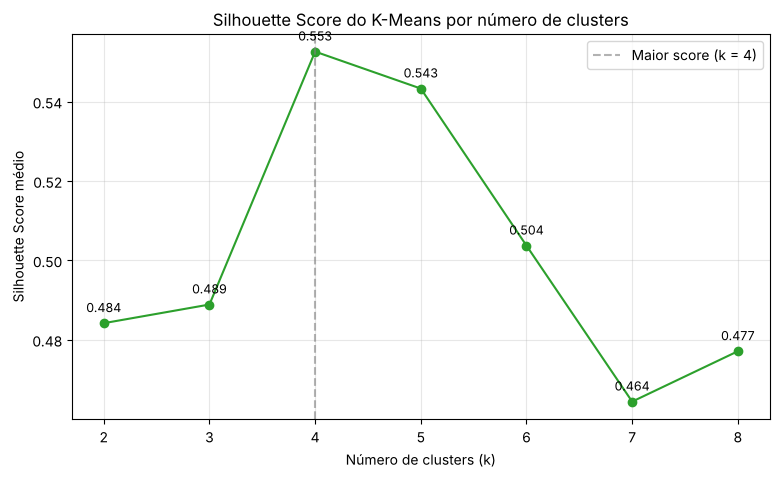

In [6]:
valores_k_sil = range(2, 9)   # k = 1 não entra: a silhueta exige ao menos 2 grupos
scores = []

for k in valores_k_sil:
    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
    rotulos = modelo.fit_predict(X_padronizado)
    # A métrica usa a MESMA matriz do ajuste, sem a coluna de clusters.
    scores.append(silhouette_score(X_padronizado, rotulos))

tabela_silhouette = pd.DataFrame({'k': list(valores_k_sil), 'silhouette_score': scores})
display(tabela_silhouette.round(4))

k_melhor_sil = tabela_silhouette.loc[tabela_silhouette['silhouette_score'].idxmax(), 'k']
print(f"Maior Silhouette Score no intervalo: k = {k_melhor_sil} "
      f"(score = {max(scores):.4f})")

plt.figure()
plt.plot(list(valores_k_sil), scores, marker='o', color='tab:green')
for k, s in zip(valores_k_sil, scores):
    plt.annotate(f'{s:.3f}', (k, s), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9)
plt.axvline(k_melhor_sil, color='gray', linestyle='--', alpha=0.6, label=f'Maior score (k = {k_melhor_sil})')
plt.title('Silhouette Score do K-Means por número de clusters')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Silhouette Score médio')
plt.xticks(list(valores_k_sil))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


**Comparação das evidências:**

| k | 2 | 3 | **4** | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|
| Silhouette | 0,4842 | 0,4889 | **0,5526** | 0,5433 | 0,5037 | 0,4644 | 0,4771 |

O **maior Silhouette Score do intervalo é 0,5526, em k = 4**. Isso **coincide** com a região do cotovelo identificada no Elbow (queda de 110,52 para 60,65 e, depois, quedas pequenas). As duas métricas medem coisas diferentes — o Elbow mede a compactação interna (inércia) e o Silhouette compara coesão com separação entre grupos — e ambas apontam para o mesmo k, o que fortalece a escolha.

Observações:
- **k = 5** tem score muito próximo (0,5433). A diferença de 0,009 é pequena, então a escolha não se apoia só nisso: com k = 5 um dos perfis seria subdividido, sem ganho claro de interpretação (ver seção 7), e a queda de inércia de 4 para 5 já é pequena.
- **k = 2 e k = 3** têm scores menores (≈ 0,48–0,49). Com k = 3, o modelo junta em um só grupo clientes de gasto alto e baixo que compram pouco e há tempo (gastos de R\$ 420 a R\$ 9.299 no mesmo cluster), perfis que pedem ações diferentes.
- Um score de 0,55 indica estrutura razoável, com grupos separados mas não isolados; alguns pontos ficam perto das fronteiras. Não é "55% de acerto".


## 6. Escolha de k e agrupamento final — 1,0 ponto

Defina `k_escolhido`, ajuste o modelo final sobre `X_padronizado` e crie `df_resultados` como uma cópia de `df`, acrescentando a coluna `cluster`.

Apresente a quantidade de clientes por grupo e o Silhouette Score final. Justifique k com base nas etapas anteriores. Os números dos clusters são apenas identificadores: cluster 2 não é necessariamente maior ou melhor que cluster 0.


In [7]:
k_escolhido = 4

modelo_final = KMeans(n_clusters=k_escolhido, random_state=42, n_init=10)
rotulos_finais = modelo_final.fit_predict(X_padronizado)

# df_resultados é uma CÓPIA: df e X_padronizado permanecem sem a coluna cluster.
df_resultados = df.copy()
df_resultados['cluster'] = rotulos_finais

print("Clientes por cluster:")
display(df_resultados['cluster'].value_counts().sort_index().rename('quantidade_clientes').to_frame())

score_final = silhouette_score(X_padronizado, rotulos_finais)
print(f"Silhouette Score final (k = {k_escolhido}): {score_final:.4f}")

# Diagnóstico extra: silhueta média por cluster e pontos com silhueta negativa.
# A média geral pode esconder um grupo mal definido; aqui conferimos isso.
from sklearn.metrics import silhouette_samples
sil_individual = silhouette_samples(X_padronizado, rotulos_finais)
display(pd.Series(sil_individual).groupby(rotulos_finais).agg(['mean', 'min']).round(3)
        .rename_axis('cluster').rename(columns={'mean': 'silhueta_media', 'min': 'silhueta_minima'}))
print("Clientes com silhueta negativa:", (sil_individual < 0).sum())

# Centroides convertidos de volta para as unidades originais (só para leitura).
centroides = pd.DataFrame(scaler.inverse_transform(modelo_final.cluster_centers_),
                          columns=variaveis).round(1)
centroides.index.name = 'cluster'
display(centroides)


Clientes por cluster:


,quantidade_clientes
cluster,
0,28
1,30
2,32
3,30


Silhouette Score final (k = 4): 0.5526


,silhueta_media,silhueta_minima
cluster,,
0,0.493,0.173
1,0.552,0.238
2,0.639,0.080
3,0.516,0.239


Clientes com silhueta negativa: 0


,gasto_total_12_meses,quantidade_compras_12_meses,dias_desde_ultima_compra
cluster,,,
0,9309.6,27.1,10.5
1,6741.4,6.3,75.6
2,2861.7,22.7,15.0
3,833.3,4.1,102.4


**k escolhido e justificativa:**

**k = 4**, pelos seguintes motivos:

1. **Elbow:** k = 4 é o ponto após o qual as quedas de inércia diminuem bruscamente (−49,9 de 3 para 4; apenas −13,7 de 4 para 5).
2. **Silhouette:** k = 4 tem o maior score do intervalo testado (**0,5526**), confirmado no modelo final.
3. **Qualidade interna:** os quatro grupos têm silhueta média entre 0,49 e 0,64 e **nenhum cliente tem silhueta negativa**, ou seja, nenhum ponto está, em média, mais próximo de outro grupo do que do seu.
4. **Interpretação:** os grupos têm tamanhos equilibrados (28, 30, 32 e 30 clientes) e perfis distintos e acionáveis (seção 7), sem grupos minúsculos ou redundantes.

Os números dos clusters (0 a 3) são apenas identificadores atribuídos pelo algoritmo; não indicam ordem, tamanho ou valor.


## 7. Visualização e interpretação — 2,0 pontos

Construa dois gráficos de dispersão, usando as cores para identificar os clusters:

1. Gasto total nos últimos 12 meses × quantidade de compras nos últimos 12 meses.
2. Gasto total nos últimos 12 meses × dias desde a última compra.

Use valores nas unidades originais, títulos, unidades nos eixos e uma legenda que identifique os grupos. Os gráficos mostram projeções em duas dimensões; o modelo utilizou três variáveis.

Crie uma tabela com a quantidade de clientes e as médias das três variáveis por cluster, nas unidades originais. Descreva cada perfil usando esses números e proponha uma ação de relacionamento para cada um. Diferencie o que os dados mostram do que ainda precisaria ser investigado.

Gasto alto não comprova renda elevada nem satisfação. Muitos dias sem comprar não comprovam que o cliente abandonou a empresa. Uma ação de reativação, fidelização ou oferta direcionada deve ser apresentada como hipótese, com os dados adicionais necessários para avaliá-la.


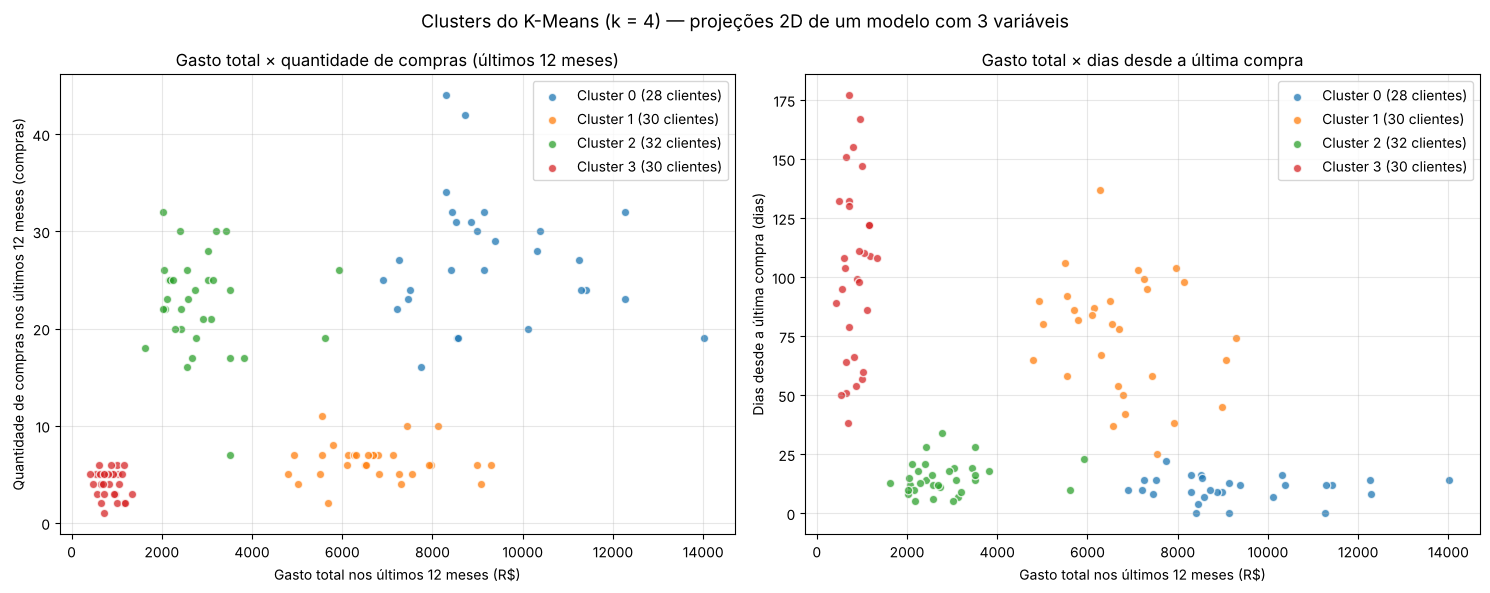

In [8]:
cores = {0: 'tab:blue', 1: 'tab:orange', 2: 'tab:green', 3: 'tab:red'}

fig, eixos = plt.subplots(1, 2, figsize=(15, 6))

# Gráfico 1: gasto × quantidade de compras (valores originais de df_resultados)
for c in sorted(df_resultados['cluster'].unique()):
    g = df_resultados[df_resultados['cluster'] == c]
    eixos[0].scatter(g['gasto_total_12_meses'], g['quantidade_compras_12_meses'],
                     color=cores[c], label=f'Cluster {c} ({len(g)} clientes)', alpha=0.75, edgecolor='white')
eixos[0].set_title('Gasto total × quantidade de compras (últimos 12 meses)')
eixos[0].set_xlabel('Gasto total nos últimos 12 meses (R$)')
eixos[0].set_ylabel('Quantidade de compras nos últimos 12 meses (compras)')
eixos[0].legend()
eixos[0].grid(alpha=0.3)

# Gráfico 2: gasto × dias desde a última compra
for c in sorted(df_resultados['cluster'].unique()):
    g = df_resultados[df_resultados['cluster'] == c]
    eixos[1].scatter(g['gasto_total_12_meses'], g['dias_desde_ultima_compra'],
                     color=cores[c], label=f'Cluster {c} ({len(g)} clientes)', alpha=0.75, edgecolor='white')
eixos[1].set_title('Gasto total × dias desde a última compra')
eixos[1].set_xlabel('Gasto total nos últimos 12 meses (R$)')
eixos[1].set_ylabel('Dias desde a última compra (dias)')
eixos[1].legend()
eixos[1].grid(alpha=0.3)

plt.suptitle(f'Clusters do K-Means (k = {k_escolhido}) — projeções 2D de um modelo com 3 variáveis', fontsize=13)
plt.tight_layout()
plt.show()


In [9]:
perfis = df_resultados.groupby('cluster').agg(
    quantidade_clientes=('id_cliente', 'count'),
    gasto_medio=('gasto_total_12_meses', 'mean'),
    compras_medias=('quantidade_compras_12_meses', 'mean'),
    dias_medios_ultima_compra=('dias_desde_ultima_compra', 'mean'),
)
# Ticket médio aproximado (gasto médio / compras médias). Não entrou no modelo:
# é apenas uma leitura derivada que ajuda a interpretar os perfis.
perfis['ticket_medio_aprox'] = perfis['gasto_medio'] / perfis['compras_medias']
display(perfis.round(1))

# Faixas (mín–máx) para ver a sobreposição entre grupos, não só as médias.
faixas = df_resultados.groupby('cluster')[variaveis].agg(['min', 'max'])
display(faixas.round(1))


,quantidade_clientes,gasto_medio,compras_medias,dias_medios_ultima_compra,ticket_medio_aprox
cluster,,,,,
0,28,9309.6,27.1,10.5,343.4
1,30,6741.4,6.3,75.6,1064.4
2,32,2861.7,22.7,15.0,126.3
3,30,833.3,4.1,102.4,204.9


gasto_total_12_meses          quantidade_compras_12_meses      \
                         min      max                         min max   
cluster                                                                 
0                     6896.3  14019.6                          16  44   
1                     4788.0   9298.7                           2  11   
2                     1625.9   5923.8                           7  32   
3                      420.0   1339.6                           1   6   

        dias_desde_ultima_compra       
                             min  max  
cluster                                
0                              0   22  
1                             25  137  
2                              5   34  
3                             38  177

**Interpretação dos perfis e ações propostas:**

Os nomes dos perfis são rótulos interpretativos dados a partir das médias; as ações são **hipóteses** a testar, não conclusões.

| Cluster | Evidências numéricas e perfil | Ação proposta | Informação adicional necessária |
| --- | --- | --- | --- |
| **0** | **28 clientes.** Gasto médio **R\$ 9.309,6** (o maior; faixa R\$ 6.896–14.020), **27,1 compras** em média (16 a 44) e última compra há **10,5 dias** (0 a 22). Ticket médio aprox. R\$ 343. **Perfil: alto valor, frequentes e recentes.** | **Fidelização/retenção:** programa de benefícios ou cashback, acesso antecipado a lançamentos, atendimento prioritário. Objetivo: manter a frequência, não dar desconto a quem já compra. | Margem de lucro por cliente (gasto alto ≠ lucro alto), taxa de devolução, satisfação/NPS e uso de cupons — para saber se são de fato rentáveis e satisfeitos. |
| **1** | **30 clientes.** Gasto médio **R\$ 6.741,4** (alto; R\$ 4.788–9.299), mas só **6,3 compras** (2 a 11) e última compra há **75,6 dias** (25 a 137). Ticket médio aprox. **R\$ 1.064**, o maior. **Perfil: alto valor por compra, esporádicos e com recência distante.** | **Reativação personalizada (hipótese):** contato com recomendações baseadas no histórico e oferta em categorias de ticket alto; testar se um lembrete/benefício reduz o intervalo entre compras. | Categorias compradas (podem ser bens duráveis, com recompra naturalmente lenta), intervalo típico entre compras, histórico de atendimento/reclamações e se o cliente ainda abre e-mails. Muitos dias sem comprar **não** provam abandono. |
| **2** | **32 clientes.** Gasto médio **R\$ 2.861,7** (R\$ 1.626–5.924), **22,7 compras** (7 a 32) e última compra há **15,0 dias** (5 a 34). Ticket médio aprox. **R\$ 126**, o menor. **Perfil: frequentes e recentes, com ticket baixo.** É o grupo mais coeso (silhueta média 0,64). | **Aumento de ticket (up-sell/cross-sell):** kits e combos, frete grátis acima de um valor mínimo, recomendações de produtos complementares. | Margem por pedido, custo de frete, categorias preferidas e sensibilidade a preço — para checar se elevar o ticket é viável sem reduzir a frequência. |
| **3** | **30 clientes.** Gasto médio **R\$ 833,3** (o menor; R\$ 420–1.340), **4,1 compras** (1 a 6) e última compra há **102,4 dias** (38 a 177), a pior recência. Ticket médio aprox. R\$ 203. **Perfil: baixo engajamento em valor, frequência e recência.** | **Reativação de baixo custo (hipótese):** campanha automatizada (e-mail/push) com cupom de recompra ou pesquisa rápida; medir resposta antes de investir mais. | Data de cadastro (podem ser clientes novos, e não perdidos), canal de aquisição, motivo de não recompra e custo de aquisição/retenção, para avaliar se vale o investimento. |

**O que os dados mostram × o que precisa ser investigado:** os dados mostram apenas *quanto*, *quantas vezes* e *há quanto tempo* cada cliente comprou. Eles **não** mostram renda, satisfação, lucro, motivo de ausência nem preferências. Rótulos como "em risco" ou "fiel" são inferências que precisam ser validadas com as informações da última coluna, idealmente por meio de testes A/B das ações propostas.


## 8. Conclusão — 1,5 ponto

Responda com base nos seus resultados:

1. Como o agrupamento ajuda a empresa a compreender os perfis de compra?
2. Por que o menor valor de inércia, isoladamente, não resolve a escolha de k?
3. Por que Silhouette Score não é uma medida de acurácia?
4. Por que é necessário separar as variáveis usadas no modelo da coluna `cluster`?
5. Apresente pelo menos duas limitações: uma sobre a base simulada e outra sobre os dados disponíveis ou o K-Means. Que dados reais você buscaria para aprimorar a análise?

**Conclusão:**

**1. Como o agrupamento ajuda a empresa.** Em vez de tratar 120 clientes individualmente ou com uma única ação, o K-Means os resumiu em **4 perfis** com comportamento distinto: alto valor frequente e recente (cluster 0, 28 clientes), alto ticket esporádico e com recência distante (cluster 1, 30), frequente e recente de ticket baixo (cluster 2, 32) e baixo engajamento (cluster 3, 30). Ao combinar valor, frequência e recência, o agrupamento separou clientes que o gasto sozinho confundiria — por exemplo, CL024 e CL097 gastaram ≈ R\$ 7.250, mas caíram nos clusters 1 e 0, respectivamente. Isso permite priorizar recursos e desenhar ações diferentes (fidelizar, reativar, aumentar ticket) e medir o resultado de cada uma.

**2. Por que a menor inércia não resolve a escolha de k.** A inércia **sempre** tende a cair quando k aumenta (de 360,00 com k = 1 até 28,41 com k = 8) e chegaria a zero com k = 120, um cluster por cliente — o que não segmenta nada. Escolher a menor inércia levaria sempre ao maior k testado. O que importa é o ponto em que o ganho adicional deixa de compensar: aqui, depois de k = 4 as quedas passam de ≈ 50 para ≈ 14 e depois ≈ 6. Por isso o Elbow é lido pela *variação* das quedas, e complementado pelo Silhouette e pela interpretação dos grupos.

**3. Por que Silhouette Score não é acurácia.** Acurácia compara previsões com **rótulos verdadeiros conhecidos**; nesta base não existe uma classificação correta. O Silhouette só mede, geometricamente, se cada ponto está mais próximo do seu grupo do que do grupo vizinho, nas distâncias do espaço padronizado. O 0,5526 obtido indica grupos razoavelmente coesos e separados, **não** "55% dos clientes classificados corretamente". Um score alto também não garante que os grupos sejam úteis para o negócio; e mudar as variáveis ou a padronização muda o score.

**4. Por que separar as variáveis do modelo da coluna `cluster`.** A coluna `cluster` é **saída** do modelo, não característica do cliente. Se fosse incluída em `X_padronizado`, ela entraria no cálculo das distâncias: pontos com o mesmo rótulo ficariam artificialmente mais próximos, inflando o Silhouette (o modelo seria avaliado com a própria resposta — vazamento de informação) e, num novo ajuste, os grupos seriam reforçados por um número arbitrário (0, 1, 2, 3 sem significado de ordem). Por isso os rótulos foram colocados apenas em `df_resultados`, uma cópia de `df`, enquanto o ajuste e a avaliação usaram somente as três variáveis padronizadas.

**5. Limitações e dados para aprimorar.**
- **Base simulada:** os 120 clientes foram gerados com NumPy (semente 303), provavelmente a partir de grupos pré-definidos; por isso os clusters aparecem relativamente bem separados. Dados reais costumam ter mais ruído, outliers, sazonalidade e grupos menos nítidos, e o k = 4 não pode ser generalizado para uma empresa real. A amostra também é pequena (120 clientes).
- **Dados disponíveis:** só há três medidas agregadas de 12 meses. Não há margem/lucro, categorias de produto, canal, data de cadastro, devoluções, satisfação ou dados demográficos. Assim, não é possível saber se um cliente de gasto alto é lucrativo, nem se muitos dias sem comprar significam abandono ou apenas um ciclo de recompra longo.
- **K-Means:** assume grupos aproximadamente esféricos e de tamanho e dispersão parecidos (usa distância euclidiana e médias); é sensível a outliers (ex.: o cliente de R\$ 14.019,61) e à escala, e exige que k seja definido antes. A variável de dias é assimétrica, o que afeta as médias. Além disso, os resultados são uma foto de um único momento; os clientes podem mudar de grupo.
- **Dados reais que buscaríamos:** histórico de pedidos com data e valor de cada compra (para calcular ticket e intervalo médio entre compras), margem por pedido, categorias compradas, data de cadastro, canal de aquisição, devoluções, cupons utilizados, interações de marketing (aberturas, cliques), NPS/avaliações e reclamações. Com isso seria possível validar os perfis, testar outras técnicas (ex.: transformação logarítmica, DBSCAN ou modelos de mistura gaussiana) e medir o impacto das ações com testes A/B.


## Entrega e critérios de avaliação

Envie na tarefa do Teams **apenas o link do repositório GitHub**, contendo:

- **Notebook Python (`.ipynb`) preenchido e executado**, com identificação, códigos, tabelas, gráficos, justificativas e conclusões.
- **README.md explicativo**, com nome e RM dos integrantes, objetivo da atividade, descrição da base de dados, orientações para executar o notebook e principais resultados encontrados.

O repositório deverá estar acessível ao professor para avaliação. A base está incorporada ao notebook; não é necessário um arquivo externo para executar a atividade. O prazo será informado na tarefa do Teams.

| Critério | Pontos |
| --- | ---: |
| Exploração e compreensão dos dados | 1,0 |
| Seleção das variáveis e padronização justificada | 1,5 |
| Elbow: implementação, gráfico e leitura | 1,5 |
| Silhouette Score: comparação, gráfico e interpretação | 1,5 |
| Modelo final e justificativa de k | 1,0 |
| Visualizações, perfis e ações fundamentadas | 2,0 |
| Conclusões e limitações | 1,5 |
| **Total** | **10,0** |

A avaliação considera a correção do código e a capacidade de explicar as escolhas e interpretar os resultados. Não há pontuação por apenas escolher um k específico sem justificativa.

### Antes de entregar

- Preencha nome(s), RM(s) e turma.
- Reinicie o ambiente e execute as células na ordem.
- Confira se as tabelas e os gráficos permanecem salvos no notebook.
- Verifique se usou as três variáveis e excluiu identificador e rótulos do cálculo das distâncias.
- Substitua os espaços de resposta por suas análises.
- Inclua o README.md e confira o acesso ao repositório.

### Documentação de apoio

- [K-Means e inércia — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
- [Silhouette Score — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html)
- [StandardScaler — scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)

Atividade de Modelagem Linear para Aprendizado de Máquina, com base simulada de clientes e aplicação exploratória de clustering.
